In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load the car dataset
df = pd.read_csv("../../dataset/CAR DETAILS FROM CAR DEKHO.csv")

# Display first 5 rows
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Number of rows: 4340
Number of columns: 8


In [4]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Column Names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 271.4 KB


In [5]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64


In [6]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 763


In [7]:
# Statistical summary of numerical columns
df.describe()


,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [8]:
print("Fuel Types:")
print(df['fuel'].value_counts())

print("\nTransmission Types:")
print(df['transmission'].value_counts())

print("\nSeller Types:")
print(df['seller_type'].value_counts())

print("\nOwner Types:")
print(df['owner'].value_counts())

Fuel Types:
fuel
Diesel      2153
Petrol      2123
CNG           40
LPG           23
Electric       1
Name: count, dtype: int64

Transmission Types:
transmission
Manual       3892
Automatic     448
Name: count, dtype: int64

Seller Types:
seller_type
Individual          3244
Dealer               994
Trustmark Dealer     102
Name: count, dtype: int64

Owner Types:
owner
First Owner             2832
Second Owner            1106
Third Owner              304
Fourth & Above Owner      81
Test Drive Car            17
Name: count, dtype: int64


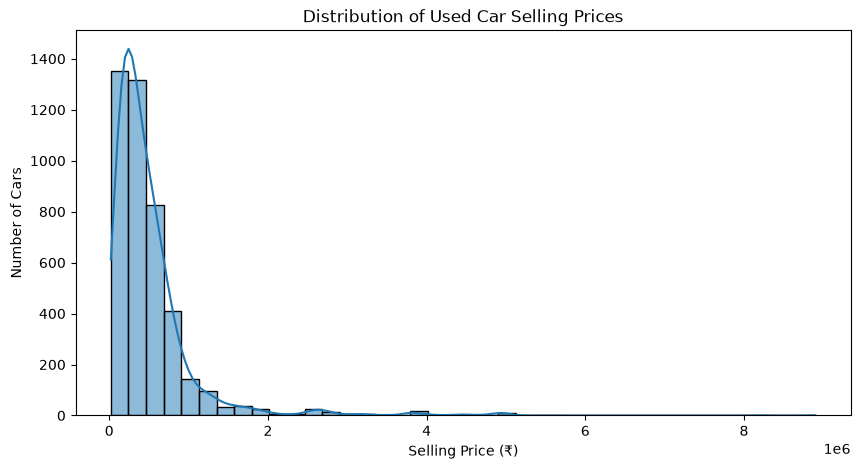

In [9]:
plt.figure(figsize=(10, 5))

sns.histplot(df['selling_price'], bins=40, kde=True)

plt.title("Distribution of Used Car Selling Prices")
plt.xlabel("Selling Price (₹)")
plt.ylabel("Number of Cars")

plt.show()

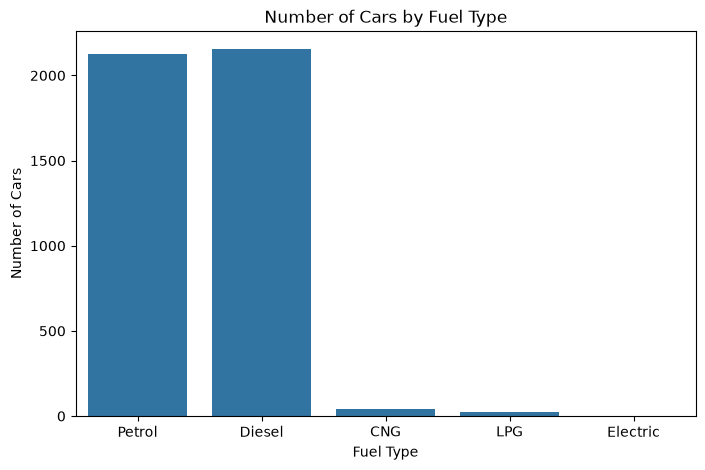

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='fuel')

plt.title("Number of Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")

plt.show()

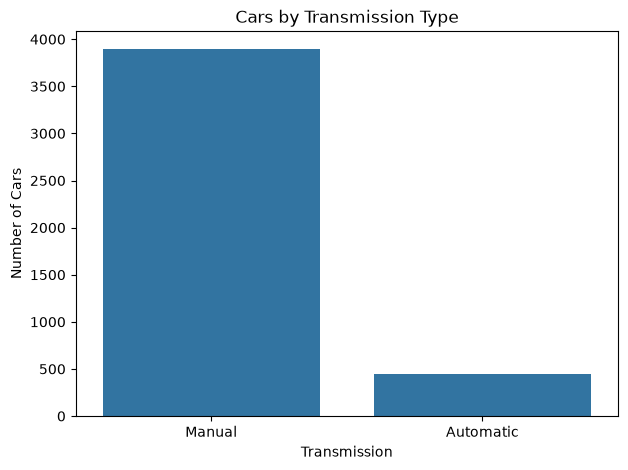

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='transmission')

plt.title("Cars by Transmission Type")
plt.xlabel("Transmission")
plt.ylabel("Number of Cars")

plt.show()

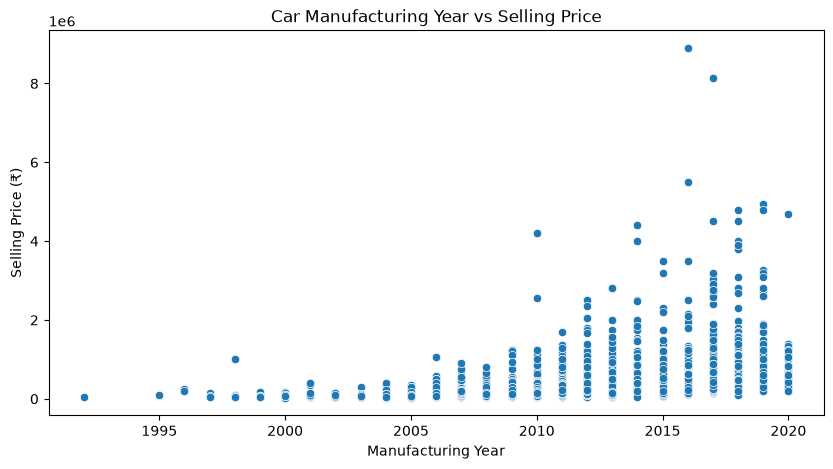

In [12]:
plt.figure(figsize=(10, 5))

sns.scatterplot(data=df, x='year', y='selling_price')

plt.title("Car Manufacturing Year vs Selling Price")
plt.xlabel("Manufacturing Year")
plt.ylabel("Selling Price (₹)")

plt.show()

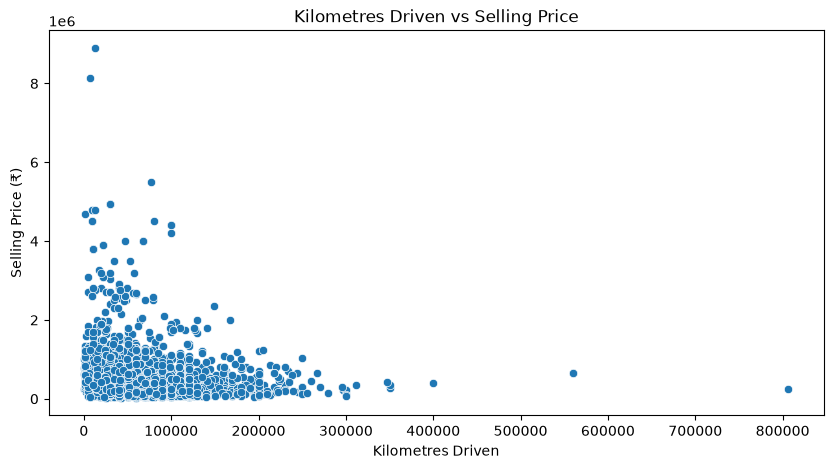

In [13]:
plt.figure(figsize=(10, 5))

sns.scatterplot(data=df, x='km_driven', y='selling_price')

plt.title("Kilometres Driven vs Selling Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price (₹)")

plt.show()

In [14]:
# Check unusual categorical values

print("Fuel categories:")
print(df['fuel'].unique())

print("\nTransmission categories:")
print(df['transmission'].unique())

print("\nOwner categories:")
print(df['owner'].unique())

print("\nSelling price range:")
print(df['selling_price'].min(), "to", df['selling_price'].max())

Fuel categories:
<StringArray>
['Petrol', 'Diesel', 'CNG', 'LPG', 'Electric']
Length: 5, dtype: str

Transmission categories:
<StringArray>
['Manual', 'Automatic']
Length: 2, dtype: str

Owner categories:
<StringArray>
[         'First Owner',         'Second Owner', 'Fourth & Above Owner',
          'Third Owner',       'Test Drive Car']
Length: 5, dtype: str

Selling price range:
20000 to 8900000


In [15]:
df[df['fuel'] == 'fuel']

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner


In [16]:
# Count duplicate records
duplicate_count = df.duplicated().sum()

print("Total duplicate records:", duplicate_count)
print("Original dataset shape:", df.shape)

Total duplicate records: 763
Original dataset shape: (4340, 8)


In [17]:
# Remove duplicate records
df = df.drop_duplicates()

# Check updated dataset
print("Dataset shape after removing duplicates:", df.shape)

print("Remaining duplicates:", df.duplicated().sum())

Dataset shape after removing duplicates: (3577, 8)
Remaining duplicates: 0


In [18]:
df.describe()

,year,selling_price,km_driven
count,3577.000000,3.577000e+03,3577.000000
mean,2012.962538,4.739125e+05,69250.545709
std,4.251759,5.093018e+05,47579.940016
min,1992.000000,2.000000e+04,1.000000
25%,2010.000000,2.000000e+05,36000.000000
50%,2013.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [19]:
# Check invalid numerical values

print("Year values less than or equal to zero:",
      (df['year'] <= 0).sum())

print("Selling prices less than or equal to zero:",
      (df['selling_price'] <= 0).sum())

print("Kilometres driven less than zero:",
      (df['km_driven'] < 0).sum())

Year values less than or equal to zero: 0
Selling prices less than or equal to zero: 0
Kilometres driven less than zero: 0


In [20]:
print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64


In [21]:
# Display some car names
print("First 20 car names:")
print(df['name'].head(20))

# Count unique car names
print("\nUnique car names:", df['name'].nunique())

First 20 car names:
0                            Maruti 800 AC
1                 Maruti Wagon R LXI Minor
2                     Hyundai Verna 1.6 SX
3                   Datsun RediGO T Option
4                    Honda Amaze VX i-DTEC
5                     Maruti Alto LX BSIII
6                Hyundai Xcent 1.2 Kappa S
7                 Tata Indigo Grand Petrol
8                 Hyundai Creta 1.6 VTVT S
9                 Maruti Celerio Green VXI
10                 Chevrolet Sail 1.2 Base
11                Tata Indigo Grand Petrol
12         Toyota Corolla Altis 1.8 VL CVT
26                    Maruti Ciaz VXi Plus
27             Hyundai Venue SX Opt Diesel
28       Chevrolet Enjoy TCDi LTZ 7 Seater
29              Jaguar XF 2.2 Litre Luxury
30    Mercedes-Benz New C-Class 220 CDI AT
31       Maruti Vitara Brezza ZDi Plus AMT
32                         Audi Q5 2.0 TDI
Name: name, dtype: str

Unique car names: 1491


In [22]:
# Extract the first word from each car name
df['brand_candidate'] = df['name'].str.split().str[0]

# Display unique brand candidates
print("Brand candidates:")
print(sorted(df['brand_candidate'].unique()))

print("\nTotal brand candidates:",
      df['brand_candidate'].nunique())

Brand candidates:
['Ambassador', 'Audi', 'BMW', 'Chevrolet', 'Daewoo', 'Datsun', 'Fiat', 'Force', 'Ford', 'Honda', 'Hyundai', 'Isuzu', 'Jaguar', 'Jeep', 'Kia', 'Land', 'MG', 'Mahindra', 'Maruti', 'Mercedes-Benz', 'Mitsubishi', 'Nissan', 'OpelCorsa', 'Renault', 'Skoda', 'Tata', 'Toyota', 'Volkswagen', 'Volvo']

Total brand candidates: 29


In [23]:
print(df['brand_candidate'].value_counts())

brand_candidate
Maruti           1072
Hyundai           637
Mahindra          328
Tata              308
Ford              220
Honda             216
Toyota            170
Chevrolet         151
Renault           110
Volkswagen         93
Nissan             52
Skoda              49
Fiat               32
Audi               31
Datsun             29
BMW                25
Mercedes-Benz      21
Jaguar              5
Mitsubishi          5
Land                5
Volvo               4
Jeep                3
Ambassador          3
MG                  2
OpelCorsa           2
Daewoo              1
Force               1
Isuzu               1
Kia                 1
Name: count, dtype: int64


In [24]:
# Check car names starting with Land
land_cars = df[df['name'].str.startswith('Land ', na=False)]

print(land_cars[['name', 'brand_candidate']].drop_duplicates())

                                                name brand_candidate
731            Land Rover Discovery Sport TD4 HSE 7S            Land
988                   Land Rover Discovery S 2.0 SD4            Land
1088       Land Rover Discovery Sport SD4 HSE Luxury            Land
3596      Land Rover Range Rover Evoque 2.2L Dynamic            Land
3875  Land Rover Range Rover 4.4 Diesel LWB Vogue SE            Land


In [25]:
# Correct the Land Rover brand
df['brand'] = df['brand_candidate'].replace({
    'Land': 'Land Rover'
})

# Check updated brand names
print(df['brand'].value_counts())

brand
Maruti           1072
Hyundai           637
Mahindra          328
Tata              308
Ford              220
Honda             216
Toyota            170
Chevrolet         151
Renault           110
Volkswagen         93
Nissan             52
Skoda              49
Fiat               32
Audi               31
Datsun             29
BMW                25
Mercedes-Benz      21
Jaguar              5
Mitsubishi          5
Land Rover          5
Volvo               4
Jeep                3
Ambassador          3
MG                  2
OpelCorsa           2
Daewoo              1
Force               1
Isuzu               1
Kia                 1
Name: count, dtype: int64


In [26]:
# Verify Land Rover entries
print(df[df['name'].str.startswith('Land ', na=False)][
    ['name', 'brand']
])

print("\nTotal unique brands:", df['brand'].nunique())

                                                name       brand
731            Land Rover Discovery Sport TD4 HSE 7S  Land Rover
988                   Land Rover Discovery S 2.0 SD4  Land Rover
1088       Land Rover Discovery Sport SD4 HSE Luxury  Land Rover
3596      Land Rover Range Rover Evoque 2.2L Dynamic  Land Rover
3875  Land Rover Range Rover 4.4 Diesel LWB Vogue SE  Land Rover

Total unique brands: 29


In [27]:
# Select input features
X = df[['name', 'brand', 'year', 'km_driven',
        'fuel', 'seller_type', 'transmission', 'owner']]

y = df['selling_price']

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nInput features:")
print(X.head())

Input features shape: (3577, 8)
Target variable shape: (3577,)

Input features:
                       name    brand  year  km_driven    fuel seller_type  \
0             Maruti 800 AC   Maruti  2007      70000  Petrol  Individual   
1  Maruti Wagon R LXI Minor   Maruti  2007      50000  Petrol  Individual   
2      Hyundai Verna 1.6 SX  Hyundai  2012     100000  Diesel  Individual   
3    Datsun RediGO T Option   Datsun  2017      46000  Petrol  Individual   
4     Honda Amaze VX i-DTEC    Honda  2014     141000  Diesel  Individual   

  transmission         owner  
0       Manual   First Owner  
1       Manual   First Owner  
2       Manual   First Owner  
3       Manual   First Owner  
4       Manual  Second Owner  


In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 2861
Testing records: 716


In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical features
numerical_features = ['year', 'km_driven']

# Categorical features
categorical_features = [
    'name', 'brand', 'fuel',
    'seller_type', 'transmission', 'owner'
]

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ]
)

print("Preprocessing setup completed successfully!")

Preprocessing setup completed successfully!


In [30]:
# Fit preprocessing on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:",
      X_train_processed.shape)

print("Testing data after preprocessing:",
      X_test_processed.shape)

Training data after preprocessing: (2861, 1349)
Testing data after preprocessing: (716, 1349)


In [31]:
print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

print("\nPreprocessing completed successfully!")

Training data shape: (2861, 1349)
Testing data shape: (716, 1349)

Preprocessing completed successfully!


In [32]:
# Import Linear Regression
from sklearn.linear_model import LinearRegression

# Create the model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train_processed, y_train)

# Predict car prices
lr_predictions = lr_model.predict(X_test_processed)

print("Linear Regression model trained successfully!")
print("Predictions generated successfully!")

Linear Regression model trained successfully!
Predictions generated successfully!


In [33]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
lr_mae = mean_absolute_error(y_test, lr_predictions)

lr_mse = mean_squared_error(y_test, lr_predictions)

lr_rmse = np.sqrt(lr_mse)

lr_r2 = r2_score(y_test, lr_predictions)

print("Linear Regression Results")
print("--------------------------")
print("MAE:", lr_mae)
print("MSE:", lr_mse)
print("RMSE:", lr_rmse)
print("R2 Score:", lr_r2)

Linear Regression Results
--------------------------
MAE: 130146.0078322944
MSE: 118527707218.67126
RMSE: 344278.5314518918
R2 Score: 0.6320539131898302


In [34]:
# Import Decision Tree Regressor
from sklearn.tree import DecisionTreeRegressor

# Create the model
dt_model = DecisionTreeRegressor(random_state=42)

# Train the model
dt_model.fit(X_train_processed, y_train)

# Predict car prices
dt_predictions = dt_model.predict(X_test_processed)

print("Decision Tree model trained successfully!")
print("Predictions generated successfully!")

Decision Tree model trained successfully!
Predictions generated successfully!


In [35]:
# Calculate evaluation metrics

dt_mae = mean_absolute_error(y_test, dt_predictions)

dt_mse = mean_squared_error(y_test, dt_predictions)

dt_rmse = np.sqrt(dt_mse)

dt_r2 = r2_score(y_test, dt_predictions)

print("Decision Tree Regression Results")
print("--------------------------------")
print("MAE:", dt_mae)
print("MSE:", dt_mse)
print("RMSE:", dt_rmse)
print("R2 Score:", dt_r2)

Decision Tree Regression Results
--------------------------------
MAE: 158719.14175977654
MSE: 148007836843.89282
RMSE: 384717.8665514416
R2 Score: 0.5405386161441776


In [36]:
# Import Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor

# Create the model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train_processed, y_train)

# Predict car prices
rf_predictions = rf_model.predict(X_test_processed)

print("Random Forest model trained successfully!")
print("Predictions generated successfully!")

Random Forest model trained successfully!
Predictions generated successfully!


In [37]:
# Calculate evaluation metrics

rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_mse = mean_squared_error(y_test, rf_predictions)

rf_rmse = np.sqrt(rf_mse)

rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Regression Results")
print("--------------------------------")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Regression Results
--------------------------------
MAE: 137383.1383854527
MSE: 128839844058.37997
RMSE: 358942.67517025606
R2 Score: 0.6000419010969807


In [38]:
# Import Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor

# Create the model
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

# Train the model
gb_model.fit(X_train_processed, y_train)

# Predict car prices
gb_predictions = gb_model.predict(X_test_processed)

print("Gradient Boosting model trained successfully!")
print("Predictions generated successfully!")

Gradient Boosting model trained successfully!
Predictions generated successfully!


In [39]:
# Calculate evaluation metrics

gb_mae = mean_absolute_error(y_test, gb_predictions)

gb_mse = mean_squared_error(y_test, gb_predictions)

gb_rmse = np.sqrt(gb_mse)

gb_r2 = r2_score(y_test, gb_predictions)

print("Gradient Boosting Regression Results")
print("------------------------------------")
print("MAE:", gb_mae)
print("MSE:", gb_mse)
print("RMSE:", gb_rmse)
print("R2 Score:", gb_r2)

Gradient Boosting Regression Results
------------------------------------
MAE: 155378.01958459383
MSE: 124236529822.05154
RMSE: 352472.0270064726
R2 Score: 0.6143319898817892


In [40]:
# Compare all four models

results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest',
        'Gradient Boosting'
    ],

    'MAE': [lr_mae, dt_mae, rf_mae, gb_mae],

    'RMSE': [lr_rmse, dt_rmse, rf_rmse, gb_rmse],

    'R2 Score': [lr_r2, dt_r2, rf_r2, gb_r2]
})

print(results.sort_values(by='R2 Score', ascending=False))

               Model            MAE           RMSE  R2 Score
0  Linear Regression  130146.007832  344278.531452  0.632054
3  Gradient Boosting  155378.019585  352472.027006  0.614332
2      Random Forest  137383.138385  358942.675170  0.600042
1      Decision Tree  158719.141760  384717.866551  0.540539


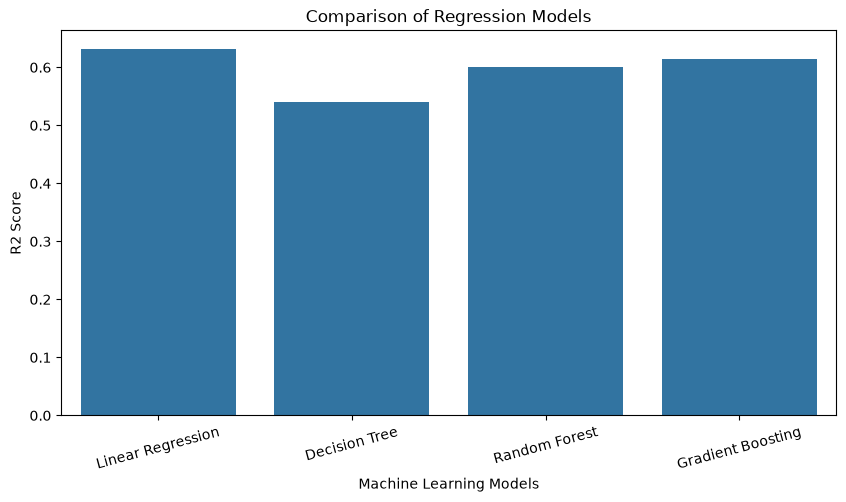

In [41]:
plt.figure(figsize=(10, 5))

sns.barplot(data=results, x='Model', y='R2 Score')

plt.title("Comparison of Regression Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=15)

plt.show()

In [42]:
import joblib
import os

# Save the best model
joblib.dump(rf_model, "../../models/random_forest_model.pkl")

# Save the preprocessing object
joblib.dump(preprocessor, "../../models/preprocessor.pkl")

print("Random Forest model saved successfully!")
print("Preprocessor saved successfully!")

Random Forest model saved successfully!
Preprocessor saved successfully!


In [43]:
# Test prediction using one sample from testing data

sample_car = X_test_processed[0].reshape(1, -1)

predicted_price = rf_model.predict(sample_car)

print("Predicted Car Price: ₹", round(predicted_price[0], 2))
print("Actual Car Price: ₹", y_test.iloc[0])

Predicted Car Price: ₹ 428266.66
Actual Car Price: ₹ 270000
